# CA2, Phase 2: The 802.11 Performance Anomaly and Airtime Fairness

This notebook loads the OMNeT++/INET simulation results from `results/`, runs the analytical models, verifies the Airtime DRR scheduler, and exports all 300-DPI figures to `../report/figures/`.

- Group parameters are loaded dynamically from `../params.json` (`host[0]` is the slow station).
- Includes both `omnetpp.scave.results` support (WSL/Linux OMNeT++ `.venv`) and a pure-Python `.sca` fallback parser (Windows `.venv`) covering both `scalar` and `statistic` (`endToEndDelay:histogram`) records.

In [13]:
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

try:
    from omnetpp.scave import results
    HAS_SCAVE = True
except ImportError:
    HAS_SCAVE = False
    print("Note: omnetpp.scave not installed; using built-in pure-Python .sca parser.")

with open(os.path.join("..", "params.json")) as f:
    P = json.load(f)

L = P["L"]
N = P["n2"]
R_SLOW = P["Rslow"]
R_FAST = P["Rfast"]
RATES = [R_SLOW] + [R_FAST] * (N - 1)  # Mbps, host[0] first
T_MEAS = 10.0  # s: 12 s simulated, 2 s warm-up

FIGURES_DIR = os.path.join("..", "report", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

print(f"students = {', '.join(P['students'])}")
print(f"n = {N}, L = {L} B, bitrates = {RATES} Mbps")

Note: omnetpp.scave not installed; using built-in pure-Python .sca parser.
students = 810102460, 810102585
n = 4, L = 1350 B, bitrates = [9, 36, 36, 36] Mbps


## Loading results

`load(config)` returns `(sc, st)`:
- `sc`: scalar records (including `itervar` and `attr` columns such as `repetition` and `quantum`)
- `st`: statistic/histogram records (including `mean`, `max`, `min`, `count`, `stddev`)

`throughput(config, direction)` returns per-repetition throughput in Mbps for each station.  
`delay(config)` returns the mean and maximum end-to-end delay per station (downlink).

In [14]:
RESULTS = "results"


def _parse_sca_fallback(pattern):
    files = sorted(glob.glob(pattern))
    if not files:
        raise FileNotFoundError(f"No .sca files matched: {pattern}")

    scalar_rows = []
    stat_rows = []
    for fp in files:
        attrs = {}
        current_stat = None
        with open(fp, "r", encoding="utf-8", errors="ignore") as f:
            for raw in f:
                line = raw.strip()
                if not line:
                    continue
                if line.startswith("attr ") or line.startswith("itervar "):
                    parts = line.split(maxsplit=2)
                    if len(parts) >= 3:
                        attrs[parts[1]] = parts[2].strip('"')
                    continue

                if line.startswith("scalar "):
                    if current_stat is not None:
                        stat_rows.append(current_stat)
                        current_stat = None
                    parts = line.split()
                    if len(parts) >= 4:
                        try:
                            val = float(parts[3])
                        except ValueError:
                            continue
                        rec = {"module": parts[1], "name": parts[2], "value": val}
                        rec.update(attrs)
                        scalar_rows.append(rec)
                elif line.startswith("statistic "):
                    if current_stat is not None:
                        stat_rows.append(current_stat)
                    parts = line.split()
                    if len(parts) >= 3:
                        current_stat = {"module": parts[1], "name": parts[2], **attrs}
                elif line.startswith("field ") and current_stat is not None:
                    parts = line.split()
                    if len(parts) >= 3:
                        try:
                            current_stat[parts[1]] = float(parts[2])
                        except ValueError:
                            pass
                elif line.startswith(("par ", "config ", "run ", "version ")):
                    if current_stat is not None:
                        stat_rows.append(current_stat)
                        current_stat = None
        if current_stat is not None:
            stat_rows.append(current_stat)

    sc = pd.DataFrame(scalar_rows)
    st = pd.DataFrame(stat_rows) if stat_rows else pd.DataFrame(
        columns=["module", "name", "mean", "max", "min", "count", "stddev", "repetition"]
    )
    return sc, st


def load(config):
    pattern = os.path.join(RESULTS, f"{config}-*.sca")
    if HAS_SCAVE:
        df = results.read_result_files(pattern)
        sc = results.get_scalars(df, include_itervars=True, include_runattrs=True)
        st = results.get_histograms(df, include_itervars=True, include_runattrs=True)
    else:
        sc, st = _parse_sca_fallback(pattern)

    for t in (sc, st):
        if not t.empty and "repetition" in t:
            t["repetition"] = pd.to_numeric(t["repetition"])
    return sc, st


def packet_counts(config, direction):
    sc, _ = load(config)
    cols = {}
    for i in range(N):
        module = f"Anomaly.server.app[{i}]" if direction == "up" else f"Anomaly.host[{i}].app[0]"
        rows = sc[(sc.module == module) & (sc.name == "packetReceived:count")]
        cols[f"host[{i}]"] = rows.set_index("repetition").value
    return pd.DataFrame(cols).sort_index()


def throughput(config, direction):
    return packet_counts(config, direction) * (8 * L) / T_MEAS / 1e6


def delay(config):
    _, st = load(config)
    d = st[st.name == "endToEndDelay:histogram"]
    return d.groupby("module")[["mean", "max"]].agg({"mean": "mean", "max": "max"})


def delay_per_rep(config):
    _, st = load(config)
    d = st[st.name == "endToEndDelay:histogram"].copy()
    cols_mean = {}
    cols_max = {}
    for i in range(N):
        mod = f"Anomaly.host[{i}].app[0]"
        sub = d[d.module == mod].set_index("repetition")
        cols_mean[f"host[{i}]"] = sub["mean"]
        cols_max[f"host[{i}]"] = sub["max"]
    return pd.DataFrame(cols_mean).sort_index(), pd.DataFrame(cols_max).sort_index()


def ci95(values):
    arr = np.asarray(values, dtype=float)
    mean = float(np.mean(arr))
    if len(arr) < 2:
        return mean, 0.0
    t_crit = float(stats.t.ppf(0.975, df=len(arr) - 1))
    hw = t_crit * float(np.std(arr, ddof=1)) / np.sqrt(len(arr))
    return mean, hw


def jains_index(vec):
    arr = np.asarray(vec, dtype=float)
    denom = len(arr) * np.sum(arr ** 2)
    return float((np.sum(arr) ** 2) / denom) if denom > 0 else 0.0

In [15]:
# Quick sanity check matching starter cell
throughput("Uplink", "up")

,host[0],host[1],host[2],host[3]
repetition,,,,
0,3.20760,3.02724,3.74760,3.52728
1,3.03372,3.49704,4.00140,3.47868
2,3.03048,3.60612,3.84156,3.34260
3,3.22812,3.34800,3.68712,3.31776
4,3.10392,3.57048,3.66228,3.36096


## 2-1 The anomaly, uplink and downlink FIFO (Questions 4-1 to 4-3)

In [16]:
# 802.11a PHY/MAC constants (20 MHz OFDM)
SIGMA = 9.0       # us
SIFS = 16.0       # us
DIFS = SIFS + 2 * SIGMA  # 34.0 us
CW_MIN = 15
K_AVG = CW_MIN / 2.0
BACKOFF_AVG = K_AVG * SIGMA  # 67.5 us

# Header breakdown for UDP/IPv4 over 802.11a (INET 4.7.0 Ieee80211LlcLpd -> Ieee8022LlcSnapHeader)
HDR_UDP = 8
HDR_IPV4 = 20
HDR_LLC_SNAP = 8
HDR_MAC = 24
HDR_FCS = 4
B_DATA = L + HDR_UDP + HDR_IPV4 + HDR_LLC_SNAP + HDR_MAC + HDR_FCS  # 1414 B
B_ACK = 14

MANDATORY_80211A = [6, 12, 24]


def ack_rate(data_rate):
    if data_rate in MANDATORY_80211A:
        return data_rate
    return max(r for r in MANDATORY_80211A if r < data_rate)


def t_ppdu_us(b_bytes, rate_mbps):
    n_dbps = 4 * rate_mbps
    n_sym = int(np.ceil((16 + 8 * b_bytes + 6) / n_dbps))
    return 20.0 + 4.0 * n_sym


ACK_RATES = [ack_rate(r) for r in RATES]
T_DATA_US = [t_ppdu_us(B_DATA, r) for r in RATES]
T_ACK_US = [t_ppdu_us(B_ACK, ar) for ar in ACK_RATES]
T_AIR_US = [td + SIFS + ta for td, ta in zip(T_DATA_US, T_ACK_US)]
T_EX_US = [DIFS + BACKOFF_AVG + td + SIFS + ta for td, ta in zip(T_DATA_US, T_ACK_US)]

print(f"MPDU B_DATA = {B_DATA} B ({8 * B_DATA} bits), B_ACK = {B_ACK} B")
for i in range(N):
    print(
        f"host[{i}]: R_data={RATES[i]} Mbps, R_ack={ACK_RATES[i]} Mbps, "
        f"T_DATA={T_DATA_US[i]:.1f} us, T_ACK={T_ACK_US[i]:.1f} us, "
        f"T_air={T_AIR_US[i]:.1f} us, T_ex={T_EX_US[i]:.1f} us"
    )

MPDU B_DATA = 1414 B (11312 bits), B_ACK = 14 B
host[0]: R_data=9 Mbps, R_ack=6 Mbps, T_DATA=1280.0 us, T_ACK=44.0 us, T_air=1340.0 us, T_ex=1441.5 us
host[1]: R_data=36 Mbps, R_ack=24 Mbps, T_DATA=336.0 us, T_ACK=28.0 us, T_air=380.0 us, T_ex=481.5 us
host[2]: R_data=36 Mbps, R_ack=24 Mbps, T_DATA=336.0 us, T_ACK=28.0 us, T_air=380.0 us, T_ex=481.5 us
host[3]: R_data=36 Mbps, R_ack=24 Mbps, T_DATA=336.0 us, T_ACK=28.0 us, T_air=380.0 us, T_ex=481.5 us


In [17]:
def summarize_config(config, direction):
    counts = packet_counts(config, direction)
    tp = counts * (8 * L) / T_MEAS / 1e6  # Mbps
    air = counts.copy()
    for i in range(N):
        air[f"host[{i}]"] = counts[f"host[{i}]"] * (T_AIR_US[i] * 1e-6) / T_MEAS

    tp_tot = tp.sum(axis=1)
    air_tot = air.sum(axis=1)
    j_s = tp.apply(lambda r: jains_index(r.values), axis=1)
    j_a = air.apply(lambda r: jains_index(r.values), axis=1)

    rows = []
    for i in range(N):
        col = f"host[{i}]"
        s_m, s_ci = ci95(tp[col])
        a_m, a_ci = ci95(air[col])
        rows.append({
            "station": col,
            "bitrate_Mbps": RATES[i],
            "S_mean_Mbps": s_m,
            "S_ci95_Mbps": s_ci,
            "a_mean": a_m,
            "a_ci95": a_ci,
        })
    summary = {
        "config": config,
        "stations": pd.DataFrame(rows),
        "S_tot_mean": ci95(tp_tot)[0],
        "S_tot_ci95": ci95(tp_tot)[1],
        "a_tot_mean": ci95(air_tot)[0],
        "J_S_mean": ci95(j_s)[0],
        "J_S_ci95": ci95(j_s)[1],
        "J_a_mean": ci95(j_a)[0],
        "J_a_ci95": ci95(j_a)[1],
        "tp_df": tp,
        "air_df": air,
    }
    return summary


res_uplink = summarize_config("Uplink", "up")
res_fifo = summarize_config("DownlinkFifo", "down")

for res in (res_uplink, res_fifo):
    print(f"=== {res['config']} ===")
    display(res["stations"])
    print(
        f"Total S = {res['S_tot_mean']:.4f} +/- {res['S_tot_ci95']:.4f} Mbps | "
        f"Sum a_i = {res['a_tot_mean']:.4f} | "
        f"J_S = {res['J_S_mean']:.4f} +/- {res['J_S_ci95']:.4f} | "
        f"J_a = {res['J_a_mean']:.4f} +/- {res['J_a_ci95']:.4f}\n"
    )

# Q4-3 Analytical FIFO throughput with and without slow station
s_fifo_pred_each = (8 * L) / sum(T_EX_US)  # Mbps (since T_EX_US is in us and 8*L is in bits -> bits/us = Mbps)
s_fifo_pred_tot = N * s_fifo_pred_each
s_fast_only_each = (8 * L) / sum(T_EX_US[1:])
s_fast_only_tot = (N - 1) * s_fast_only_each
fast_sim_mean = res_fifo["stations"].loc[1:, "S_mean_Mbps"].mean()
slow_share_of_air = res_fifo["stations"].loc[0, "a_mean"] / res_fifo["a_tot_mean"]
fast_degradation_pct = (s_fast_only_each - s_fifo_pred_each) / s_fast_only_each * 100.0
fast_degradation_sim_pct = (s_fast_only_each - fast_sim_mean) / s_fast_only_each * 100.0

print(f"Q4-3 Analytical DownlinkFifo (with host[0]): S_i = {s_fifo_pred_each:.4f} Mbps, S_tot = {s_fifo_pred_tot:.4f} Mbps")
print(f"Q4-3 Simulation DownlinkFifo: S_tot = {res_fifo['S_tot_mean']:.4f} Mbps (rel err = {abs(res_fifo['S_tot_mean'] - s_fifo_pred_tot)/s_fifo_pred_tot*100:.3f}%)")
print(f"Q4-3 Analytical without host[0] (n-1={N-1} fast): S_fast_only = {s_fast_only_each:.4f} Mbps, S_tot = {s_fast_only_tot:.4f} Mbps")
print(f"Q4-3 Fast-station throughput reduction due to host[0]: {fast_degradation_pct:.2f}% (analytical), {fast_degradation_sim_pct:.2f}% (vs sim)")
print(f"Q4-2 Slow-station fraction of channel airtime in DownlinkFifo: a_0 = {res_fifo['stations'].loc[0, 'a_mean']:.4f} ({slow_share_of_air*100:.2f}% of active airtime)")

=== Uplink ===


,station,bitrate_Mbps,S_mean_Mbps,S_ci95_Mbps,a_mean,a_ci95
0,host[0],9,3.120768,0.116275,0.387206,0.014427
1,host[1],36,3.409776,0.292610,0.119974,0.010296
2,host[2],36,3.787992,0.171177,0.133281,0.006023
3,host[3],36,3.405456,0.114179,0.119822,0.004017


Total S = 13.7240 +/- 0.2473 Mbps | Sum a_i = 0.7603 | J_S = 0.9939 +/- 0.0034 | J_a = 0.7355 +/- 0.0262

=== DownlinkFifo ===


,station,bitrate_Mbps,S_mean_Mbps,S_ci95_Mbps,a_mean,a_ci95
0,host[0],9,3.752352,0.053309,0.465570,0.006614
1,host[1],36,3.755160,0.087191,0.132126,0.003068
2,host[2],36,3.726216,0.107013,0.131108,0.003765
3,host[3],36,3.725352,0.118648,0.131077,0.004175


Total S = 14.9591 +/- 0.1107 Mbps | Sum a_i = 0.8599 | J_S = 0.9997 +/- 0.0001 | J_a = 0.6882 +/- 0.0105

Q4-3 Analytical DownlinkFifo (with host[0]): S_i = 3.7422 Mbps, S_tot = 14.9688 Mbps
Q4-3 Simulation DownlinkFifo: S_tot = 14.9591 Mbps (rel err = 0.065%)
Q4-3 Analytical without host[0] (n-1=3 fast): S_fast_only = 7.4766 Mbps, S_tot = 22.4299 Mbps
Q4-3 Fast-station throughput reduction due to host[0]: 49.95% (analytical), 50.04% (vs sim)
Q4-2 Slow-station fraction of channel airtime in DownlinkFifo: a_0 = 0.4656 (54.14% of active airtime)


## 2-2 Your airtime-fair scheduler (Questions 4-4 to 4-6)

In [18]:
# Q4-4 Analytical prediction under equal headAirtime (= T_DATA_i) allocation
denom_drr = sum(tex / tdata for tex, tdata in zip(T_EX_US, T_DATA_US))
S_DRR_PRED = [(8 * L / tdata) / denom_drr for tdata in T_DATA_US]
S_DRR_PRED_TOT = sum(S_DRR_PRED)

res_drr = summarize_config("DownlinkAirtime", "down")

print("=== Q4-4 vs Q4-5: DownlinkAirtime ===")
comp = res_drr["stations"].copy()
comp["S_pred_Mbps"] = S_DRR_PRED
comp["rel_err_pct"] = (comp["S_mean_Mbps"] - comp["S_pred_Mbps"]).abs() / comp["S_pred_Mbps"] * 100.0
display(comp)

tot_gain_pct = (res_drr["S_tot_mean"] - res_fifo["S_tot_mean"]) / res_fifo["S_tot_mean"] * 100.0
slow_drop_pct = (res_fifo["stations"].loc[0, "S_mean_Mbps"] - res_drr["stations"].loc[0, "S_mean_Mbps"]) / res_fifo["stations"].loc[0, "S_mean_Mbps"] * 100.0

print(
    f"Total S_drr = {res_drr['S_tot_mean']:.4f} +/- {res_drr['S_tot_ci95']:.4f} Mbps "
    f"(pred = {S_DRR_PRED_TOT:.4f} Mbps, err = {abs(res_drr['S_tot_mean'] - S_DRR_PRED_TOT)/S_DRR_PRED_TOT*100:.3f}%)"
)
print(f"Total throughput gain vs DownlinkFifo: +{tot_gain_pct:.2f}%")
print(f"Slow station (host[0]) throughput change vs DownlinkFifo: -{slow_drop_pct:.2f}%")
print(f"J_S = {res_drr['J_S_mean']:.4f} +/- {res_drr['J_S_ci95']:.4f}, J_a = {res_drr['J_a_mean']:.4f} +/- {res_drr['J_a_ci95']:.4f}")
print(
    f"Why J_a != 1: headAirtime counts T_DATA ({T_DATA_US[0]:.0f} vs {T_DATA_US[1]:.0f} us), "
    f"while a_i also counts SIFS+T_ACK ({T_AIR_US[0]:.0f} vs {T_AIR_US[1]:.0f} us; "
    f"overhead ratio {T_AIR_US[0]/T_DATA_US[0]:.4f} vs {T_AIR_US[1]/T_DATA_US[1]:.4f})."
)

=== Q4-4 vs Q4-5: DownlinkAirtime ===


,station,bitrate_Mbps,S_mean_Mbps,S_ci95_Mbps,a_mean,a_ci95,S_pred_Mbps,rel_err_pct
0,host[0],9,1.55439,0.000859,0.192860,0.000107,1.555220,0.053340
1,host[1],36,5.92245,0.002578,0.208382,0.000091,5.924646,0.037064
2,host[2],36,5.92272,0.001403,0.208392,0.000049,5.924646,0.032507
3,host[3],36,5.92272,0.001984,0.208392,0.000070,5.924646,0.032507


Total S_drr = 19.3223 +/- 0.0061 Mbps (pred = 19.3292 Mbps, err = 0.036%)
Total throughput gain vs DownlinkFifo: +29.17%
Slow station (host[0]) throughput change vs DownlinkFifo: -58.58%
J_S = 0.8671 +/- 0.0000, J_a = 0.9989 +/- 0.0000
Why J_a != 1: headAirtime counts T_DATA (1280 vs 336 us), while a_i also counts SIFS+T_ACK (1340 vs 380 us; overhead ratio 1.0469 vs 1.1310).


In [19]:
# Q4-6 Verification: first 10 scheduling decisions for 2 stations (1 slow @ 9 Mbps, 1 fast @ 36 Mbps)
def trace_two_station_drr(steps=10, quantum=500.0):
    t_head = [T_DATA_US[0], T_DATA_US[1]]
    deficit = [0.0, 0.0]
    current = 0
    rows = []
    for step in range(1, steps + 1):
        d_before = list(deficit)
        c_start = current
        rounds = 0
        while True:
            if deficit[current] <= 0.0:
                deficit[current] += quantum
                current = (current + 1) % 2
                rounds += 1
            else:
                served = current
                deficit[served] -= t_head[served]
                rows.append({
                    "decision": step,
                    "start_curr": c_start,
                    "d0_before": d_before[0],
                    "d1_before": d_before[1],
                    "served": f"host[{served}]",
                    "cost_us": t_head[served],
                    "d0_after": deficit[0],
                    "d1_after": deficit[1],
                })
                break
    return pd.DataFrame(rows)


trace_df = trace_two_station_drr(10, quantum=500.0)
display(trace_df)

,decision,start_curr,d0_before,d1_before,served,cost_us,d0_after,d1_after
0,1,0,0.0,0.0,host[0],1280.0,-780.0,500.0
1,2,0,-780.0,500.0,host[1],336.0,-280.0,164.0
2,3,1,-280.0,164.0,host[1],336.0,-280.0,-172.0
3,4,1,-280.0,-172.0,host[1],336.0,220.0,-8.0
4,5,1,220.0,-8.0,host[0],1280.0,-1060.0,492.0
5,6,0,-1060.0,492.0,host[1],336.0,-560.0,156.0
6,7,1,-560.0,156.0,host[1],336.0,-560.0,-180.0
7,8,1,-560.0,-180.0,host[1],336.0,-60.0,-16.0
8,9,1,-60.0,-16.0,host[1],336.0,440.0,148.0
9,10,1,440.0,148.0,host[1],336.0,440.0,-188.0


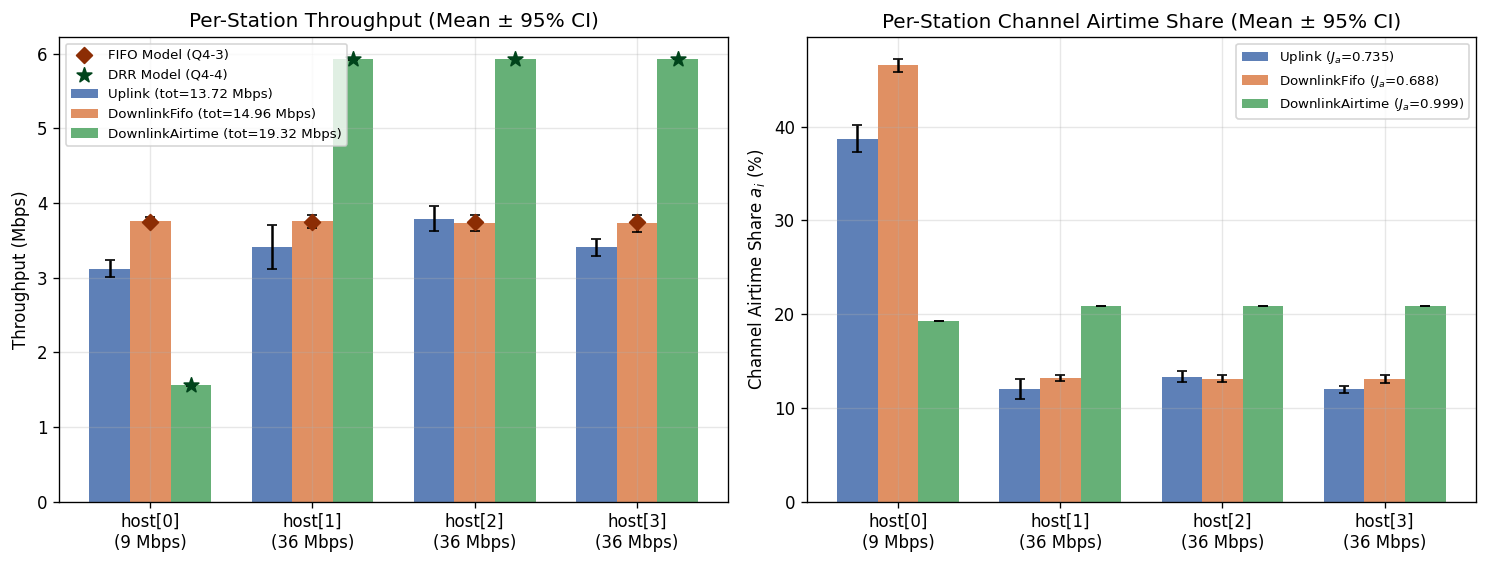

In [20]:
# Figure 1: Throughput and Airtime Share across Uplink, DownlinkFifo, DownlinkAirtime
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))

x = np.arange(N)
w = 0.25
configs = [
    ("Uplink", res_uplink, "#4C72B0"),
    ("DownlinkFifo", res_fifo, "#DD8452"),
    ("DownlinkAirtime", res_drr, "#55A868"),
]

for idx, (label, res, color) in enumerate(configs):
    offset = (idx - 1) * w
    s_means = res["stations"]["S_mean_Mbps"].values
    s_cis = res["stations"]["S_ci95_Mbps"].values
    a_means = res["stations"]["a_mean"].values * 100.0
    a_cis = res["stations"]["a_ci95"].values * 100.0
    ax1.bar(x + offset, s_means, w, yerr=s_cis, capsize=3, label=f"{label} (tot={res['S_tot_mean']:.2f} Mbps)", color=color, alpha=0.9)
    ax2.bar(x + offset, a_means, w, yerr=a_cis, capsize=3, label=f"{label} ($J_a$={res['J_a_mean']:.3f})", color=color, alpha=0.9)

# Overlay analytical predictions on throughput plot
ax1.scatter(x, [s_fifo_pred_each] * N, marker="D", s=45, color="#8C2D04", zorder=5, label="FIFO Model (Q4-3)")
ax1.scatter(x + w, S_DRR_PRED, marker="*", s=85, color="#00441B", zorder=5, label="DRR Model (Q4-4)")

xtick_labels = [f"host[{i}]\n({RATES[i]} Mbps)" for i in range(N)]
ax1.set_xticks(x)
ax1.set_xticklabels(xtick_labels)
ax1.set_ylabel("Throughput (Mbps)")
ax1.set_title("Per-Station Throughput (Mean ± 95% CI)")
ax1.legend(fontsize=8)

ax2.set_xticks(x)
ax2.set_xticklabels(xtick_labels)
ax2.set_ylabel("Channel Airtime Share $a_i$ (%)")
ax2.set_title("Per-Station Channel Airtime Share (Mean ± 95% CI)")
ax2.legend(fontsize=8)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "phase2_throughput_airtime_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()

## 2-3 Analysis and limits (Questions 4-7 to 4-9 + Quantum sensitivity)

In [21]:
# Q4-7: Little's Law end-to-end delay prediction vs simulation
K_FIFO = 100.0
K_DRR = 50.0

lambda_fifo_tot = (res_fifo["S_tot_mean"] * 1e6) / (8 * L)  # pkt/s
w_fifo_pred_ms = (K_FIFO / lambda_fifo_tot) * 1e3

w_drr_pred_ms = []
for i in range(N):
    lam_i = (res_drr["stations"].loc[i, "S_mean_Mbps"] * 1e6) / (8 * L)
    w_drr_pred_ms.append((K_DRR / lam_i) * 1e3)

fifo_d_mean, fifo_d_max = delay_per_rep("DownlinkFifo")
drr_d_mean, drr_d_max = delay_per_rep("DownlinkAirtime")

delay_rows = []
for i in range(N):
    col = f"host[{i}]"
    fm, fci = ci95(fifo_d_mean[col] * 1e3)
    dm, dci = ci95(drr_d_mean[col] * 1e3)
    delay_rows.append({
        "station": col,
        "FIFO_pred_ms": w_fifo_pred_ms,
        "FIFO_sim_mean_ms": fm,
        "FIFO_sim_ci95_ms": fci,
        "FIFO_sim_max_ms": fifo_d_max[col].max() * 1e3,
        "DRR_pred_ms": w_drr_pred_ms[i],
        "DRR_sim_mean_ms": dm,
        "DRR_sim_ci95_ms": dci,
        "DRR_sim_max_ms": drr_d_max[col].max() * 1e3,
    })

delay_comp = pd.DataFrame(delay_rows)
print("=== Q4-7: End-to-End Delay (Little's Law vs Simulation) ===")
display(delay_comp)

=== Q4-7: End-to-End Delay (Little's Law vs Simulation) ===


,station,FIFO_pred_ms,FIFO_sim_mean_ms,FIFO_sim_ci95_ms,FIFO_sim_max_ms,DRR_pred_ms,DRR_sim_mean_ms,DRR_sim_ci95_ms,DRR_sim_max_ms
0,host[0],72.196953,74.257567,0.596387,87.317350,347.403161,349.111145,0.084944,352.301589
1,host[1],72.196953,73.287680,0.526417,86.453641,91.178482,92.011027,0.034299,96.392695
2,host[2],72.196953,73.271989,0.565006,87.320099,91.174325,92.137080,0.246162,95.895689
3,host[3],72.196953,73.333949,0.475985,86.335524,91.174325,92.135852,0.222078,96.217674


In [22]:
# Q4-8: Low-load slow station (server.app[0].sendInterval = exponential(25ms))
res_fifo_low = summarize_config("DownlinkFifoLowLoad", "down")
res_drr_low = summarize_config("DownlinkAirtimeLowLoad", "down")

low_fifo_d_mean, low_fifo_d_max = delay_per_rep("DownlinkFifoLowLoad")
low_drr_d_mean, low_drr_d_max = delay_per_rep("DownlinkAirtimeLowLoad")

# Offered load of host[0] from server.app[0]
def offered_slow_mbps(config):
    sc, _ = load(config)
    rows = sc[(sc.module == "Anomaly.server.app[0]") & (sc.name == "packetSent:count")]
    # packetSent:count records packets sent after warmup-period (over T_MEAS = 10s)
    vals = rows["value"].values * (8 * L) / T_MEAS / 1e6
    return ci95(vals)

off_fifo_m, off_fifo_ci = offered_slow_mbps("DownlinkFifoLowLoad")
off_drr_m, off_drr_ci = offered_slow_mbps("DownlinkAirtimeLowLoad")

print(f"Theoretical offered load for host[0] (1 pkt / 25 ms): {(8*L/0.025)/1e6:.4f} Mbps")
print(f"Measured server.app[0] send rate: FIFO = {off_fifo_m:.4f} +/- {off_fifo_ci:.4f} Mbps | DRR = {off_drr_m:.4f} +/- {off_drr_ci:.4f} Mbps")

for name, res, dm_df, dx_df in [
    ("DownlinkFifoLowLoad", res_fifo_low, low_fifo_d_mean, low_fifo_d_max),
    ("DownlinkAirtimeLowLoad", res_drr_low, low_drr_d_mean, low_drr_d_max),
]:
    tbl = res["stations"].copy()
    tbl["delay_mean_ms"] = [ci95(dm_df[f"host[{i}]"] * 1e3)[0] for i in range(N)]
    tbl["delay_ci95_ms"] = [ci95(dm_df[f"host[{i}]"] * 1e3)[1] for i in range(N)]
    tbl["delay_max_ms"] = [dx_df[f"host[{i}]"].max() * 1e3 for i in range(N)]
    print(f"=== {name} (S_tot = {res['S_tot_mean']:.4f} +/- {res['S_tot_ci95']:.4f} Mbps, J_S={res['J_S_mean']:.4f}, J_a={res['J_a_mean']:.4f}) ===")
    display(tbl)

Theoretical offered load for host[0] (1 pkt / 25 ms): 0.4320 Mbps
Measured server.app[0] send rate: FIFO = 0.4290 +/- 0.0174 Mbps | DRR = 0.4383 +/- 0.0189 Mbps
=== DownlinkFifoLowLoad (S_tot = 22.3949 +/- 0.0137 Mbps, J_S=0.7509, J_a=0.7531) ===


,station,bitrate_Mbps,S_mean_Mbps,S_ci95_Mbps,a_mean,a_ci95,delay_mean_ms,delay_ci95_ms,delay_max_ms
0,host[0],9,0.013176,0.004387,0.001635,0.000544,50.024289,0.146527,51.811295
1,host[1],36,7.480728,0.045924,0.263211,0.001616,49.047883,0.023475,51.911063
2,host[2],36,7.463016,0.035888,0.262588,0.001263,49.054525,0.027529,51.882392
3,host[3],36,7.437960,0.049608,0.261706,0.001745,49.048506,0.035625,51.939391


=== DownlinkAirtimeLowLoad (S_tot = 21.5503 +/- 0.0364 Mbps, J_S=0.7805, J_a=0.8503) ===


,station,bitrate_Mbps,S_mean_Mbps,S_ci95_Mbps,a_mean,a_ci95,delay_mean_ms,delay_ci95_ms,delay_max_ms
0,host[0],9,0.438912,0.018836,0.054458,0.002337,6.046526,0.049593,26.577529
1,host[1],36,7.037712,0.017931,0.247623,0.000631,77.554419,0.202040,91.245119
2,host[2],36,7.036848,0.018908,0.247593,0.000665,77.554084,0.198695,91.262421
3,host[3],36,7.036848,0.018279,0.247593,0.000643,77.542714,0.227724,90.881219


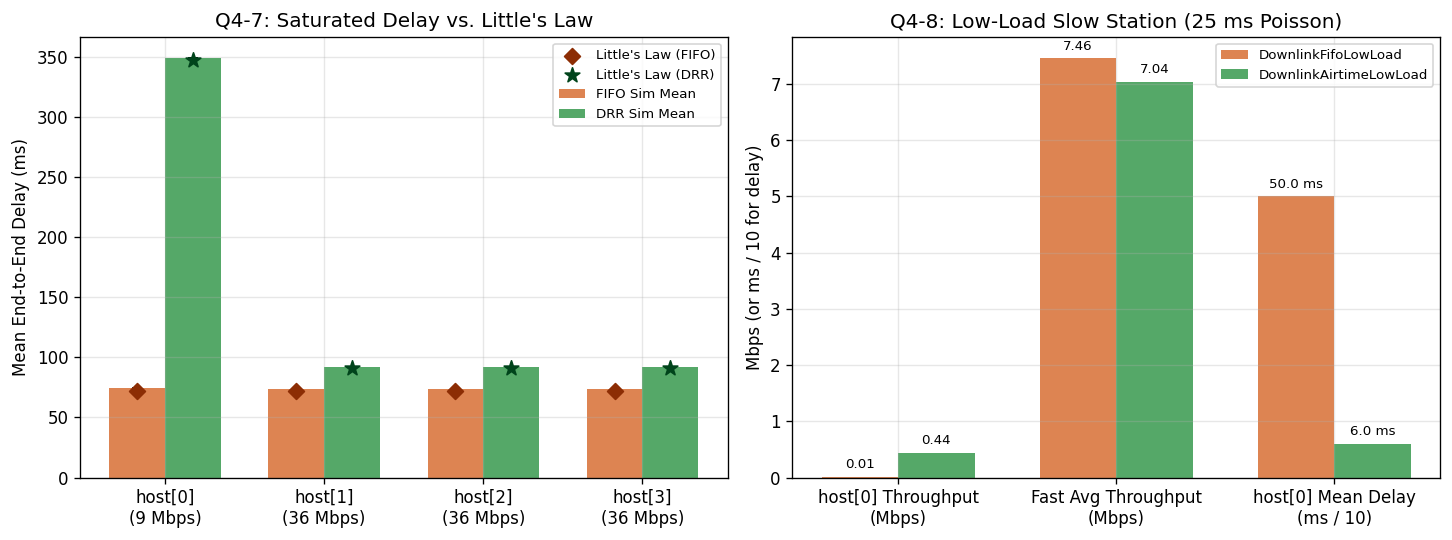

In [23]:
# Figure 2: Delay Comparison (Saturated FIFO vs DRR + Little's Law, and Low-Load host[0])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.6))

x = np.arange(N)
w = 0.35
ax1.bar(x - w / 2, delay_comp["FIFO_sim_mean_ms"], w, yerr=delay_comp["FIFO_sim_ci95_ms"], capsize=3, label="FIFO Sim Mean", color="#DD8452")
ax1.bar(x + w / 2, delay_comp["DRR_sim_mean_ms"], w, yerr=delay_comp["DRR_sim_ci95_ms"], capsize=3, label="DRR Sim Mean", color="#55A868")
ax1.scatter(x - w / 2, delay_comp["FIFO_pred_ms"], marker="D", s=45, color="#8C2D04", zorder=5, label="Little's Law (FIFO)")
ax1.scatter(x + w / 2, delay_comp["DRR_pred_ms"], marker="*", s=85, color="#00441B", zorder=5, label="Little's Law (DRR)")
ax1.set_xticks(x)
ax1.set_xticklabels([f"host[{i}]\n({RATES[i]} Mbps)" for i in range(N)])
ax1.set_ylabel("Mean End-to-End Delay (ms)")
ax1.set_title("Q4-7: Saturated Delay vs. Little's Law")
ax1.legend(fontsize=8)

# Low-load comparison (Throughput + host[0] delay)
cats = ["host[0] Throughput\n(Mbps)", "Fast Avg Throughput\n(Mbps)", "host[0] Mean Delay\n(ms / 10)"]
fifo_vals = [
    res_fifo_low["stations"].loc[0, "S_mean_Mbps"],
    res_fifo_low["stations"].loc[1:, "S_mean_Mbps"].mean(),
    ci95(low_fifo_d_mean["host[0]"] * 1e3)[0] / 10.0,
]
drr_vals = [
    res_drr_low["stations"].loc[0, "S_mean_Mbps"],
    res_drr_low["stations"].loc[1:, "S_mean_Mbps"].mean(),
    ci95(low_drr_d_mean["host[0]"] * 1e3)[0] / 10.0,
]
cx = np.arange(len(cats))
ax2.bar(cx - w / 2, fifo_vals, w, label="DownlinkFifoLowLoad", color="#DD8452")
ax2.bar(cx + w / 2, drr_vals, w, label="DownlinkAirtimeLowLoad", color="#55A868")
for idx, (fv, dv) in enumerate(zip(fifo_vals, drr_vals)):
    lbl_f = f"{fv*10:.1f} ms" if idx == 2 else f"{fv:.2f}"
    lbl_d = f"{dv*10:.1f} ms" if idx == 2 else f"{dv:.2f}"
    ax2.text(idx - w / 2, fv + 0.15, lbl_f, ha="center", fontsize=8)
    ax2.text(idx + w / 2, dv + 0.15, lbl_d, ha="center", fontsize=8)
ax2.set_xticks(cx)
ax2.set_xticklabels(cats)
ax2.set_ylabel("Mbps (or ms / 10 for delay)")
ax2.set_title("Q4-8: Low-Load Slow Station (25 ms Poisson)")
ax2.legend(fontsize=8)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "phase2_delay_and_lowload.png"), dpi=300, bbox_inches="tight")
plt.show()

=== Quantum Sensitivity Sweep ===


,quantum_us,S_slow_Mbps,S_fast_Mbps,S_tot_Mbps,S_tot_ci95,J_a,slow_delay_mean_ms
0,200.0,1.554984,5.923800,19.326384,0.021275,0.998925,349.039268
1,500.0,1.555416,5.925528,19.332000,0.010300,0.998925,348.920670
2,1000.0,1.554768,5.924376,19.327896,0.011972,0.998919,349.016895
3,2000.0,1.555632,5.924664,19.329624,0.009735,0.998932,349.297454


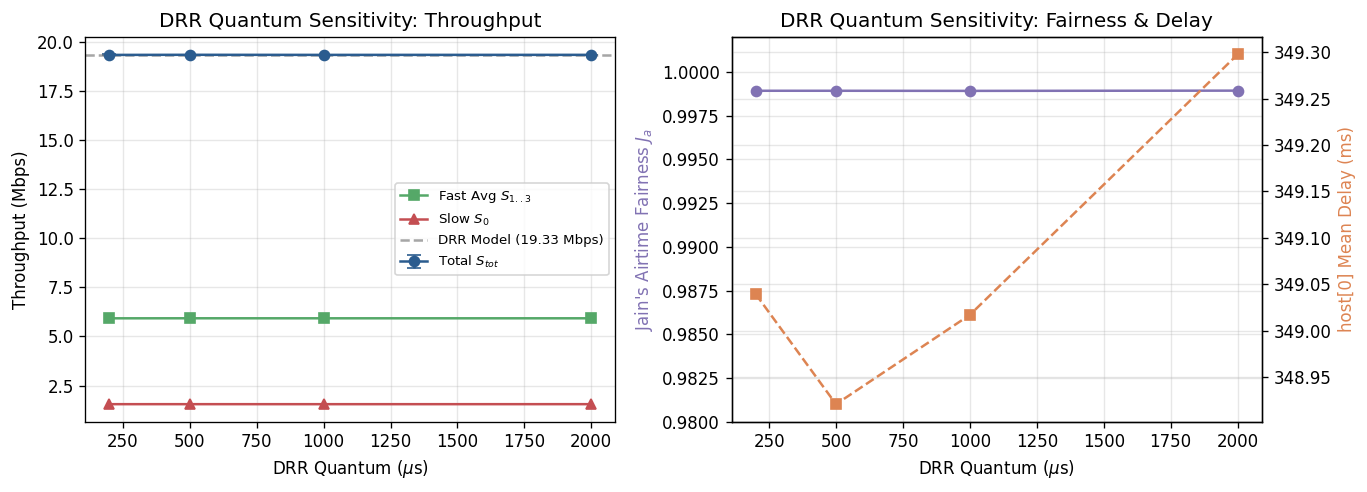

In [24]:
# Sensitivity Sweep over Quantum (200us, 500us, 1000us, 2000us)
sc_q, st_q = load("QuantumSweep")
sc_q["quantum_us"] = sc_q["quantum"].str.replace("us", "", regex=False).astype(float)
st_q["quantum_us"] = st_q["quantum"].str.replace("us", "", regex=False).astype(float)

q_vals = sorted(sc_q["quantum_us"].unique())
q_rows = []
for qv in q_vals:
    sub_sc = sc_q[sc_q["quantum_us"] == qv]
    sub_st = st_q[(st_q["quantum_us"] == qv) & (st_q["name"] == "endToEndDelay:histogram")]
    tp_cols = {}
    air_cols = {}
    for i in range(N):
        mod = f"Anomaly.host[{i}].app[0]"
        cnt = sub_sc[(sub_sc.module == mod) & (sub_sc.name == "packetReceived:count")].set_index("repetition").value
        tp_cols[f"host[{i}]"] = cnt * (8 * L) / T_MEAS / 1e6
        air_cols[f"host[{i}]"] = cnt * (T_AIR_US[i] * 1e-6) / T_MEAS
    tp_df = pd.DataFrame(tp_cols)
    air_df = pd.DataFrame(air_cols)
    j_a_vals = air_df.apply(lambda r: jains_index(r.values), axis=1)
    d_slow = sub_st[sub_st.module == "Anomaly.host[0].app[0]"]["mean"].values * 1e3
    q_rows.append({
        "quantum_us": qv,
        "S_slow_Mbps": ci95(tp_df["host[0]"])[0],
        "S_fast_Mbps": ci95(tp_df[[f"host[{i}]" for i in range(1, N)]].mean(axis=1))[0],
        "S_tot_Mbps": ci95(tp_df.sum(axis=1))[0],
        "S_tot_ci95": ci95(tp_df.sum(axis=1))[1],
        "J_a": ci95(j_a_vals)[0],
        "slow_delay_mean_ms": ci95(d_slow)[0],
    })

q_df = pd.DataFrame(q_rows)
print("=== Quantum Sensitivity Sweep ===")
display(q_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax1.errorbar(q_df["quantum_us"], q_df["S_tot_Mbps"], yerr=q_df["S_tot_ci95"], marker="o", capsize=4, label="Total $S_{tot}$", color="#2B5C8F")
ax1.plot(q_df["quantum_us"], q_df["S_fast_Mbps"], marker="s", label="Fast Avg $S_{1..3}$", color="#55A868")
ax1.plot(q_df["quantum_us"], q_df["S_slow_Mbps"], marker="^", label="Slow $S_0$", color="#C44E52")
ax1.axhline(S_DRR_PRED_TOT, ls="--", color="gray", alpha=0.7, label=f"DRR Model ({S_DRR_PRED_TOT:.2f} Mbps)")
ax1.set_xlabel(r"DRR Quantum ($\mu$s)")
ax1.set_ylabel("Throughput (Mbps)")
ax1.set_title("DRR Quantum Sensitivity: Throughput")
ax1.legend(fontsize=8)

ax2.plot(q_df["quantum_us"], q_df["J_a"], marker="o", color="#8172B3", label="Airtime Fairness $J_a$")
ax2_r = ax2.twinx()
ax2_r.plot(q_df["quantum_us"], q_df["slow_delay_mean_ms"], marker="s", ls="--", color="#DD8452", label="host[0] Mean Delay (ms)")
ax2.set_xlabel(r"DRR Quantum ($\mu$s)")
ax2.set_ylabel("Jain's Airtime Fairness $J_a$", color="#8172B3")
ax2_r.set_ylabel("host[0] Mean Delay (ms)", color="#DD8452")
ax2.set_ylim(0.98, 1.002)
ax2.set_title("DRR Quantum Sensitivity: Fairness & Delay")

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "phase2_quantum_sweep.png"), dpi=300, bbox_inches="tight")
plt.show()